# 03 · Descripción de las muestras

**Sección de la tesis:** 6.1 (Descripción de las muestras).

**Entrada:** `data_processed/03_catalogo_con_parametros_derivados.csv`

**Salidas:** tablas D-T3, D-T4, D-T5 y D-T8; figuras D-F1 a D-F4.

> En PSCompPars, los radios de planetas que no transitan y las masas de planetas sin medición dinámica son **estimaciones del archivo** a partir de una relación masa–radio. Por eso las figuras de radio distinguen los planetas observados en tránsito, y el diagrama masa–radio usa solo masas verdaderas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

In [2]:
df = cargar_catalogo()
print("Planetas:", len(df), "| estrellas anfitrionas:", df["hostname"].nunique())

Planetas: 6267 | estrellas anfitrionas: 4711


## 6.1.1 Catálogo general y disponibilidad de parámetros

### Datos faltantes

Figura D-F1 guardada: figuras/D-F1_datos_faltantes_por_variable.png y .pdf


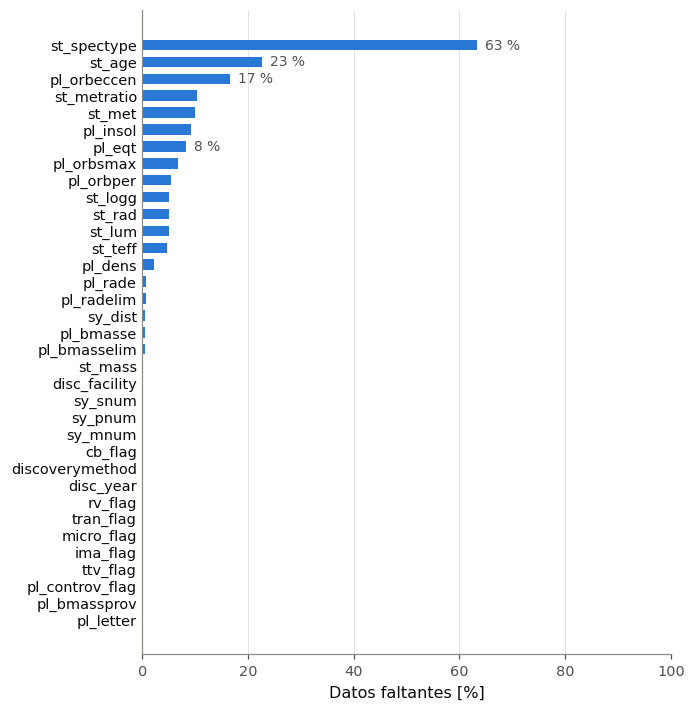

In [3]:
originales = [c for c in COLUMNAS_TRABAJO if c not in ("pl_name", "hostname")]
faltantes = (100 * df[originales].isna().mean()).sort_values()

fig, ax = plt.subplots(figsize=(6.2, 7.6))
ax.barh(faltantes.index, faltantes.values, height=0.62, color=COLOR_UNICO)
ax.set_xlabel("Datos faltantes [%]")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=TINTA)
for variable in ["st_spectype", "st_age", "pl_eqt", "pl_orbeccen"]:
    ax.text(faltantes[variable] + 1.5, variable, f"{faltantes[variable]:.0f} %",
            va="center", fontsize=9, color=TINTA_SECUNDARIA)
guardar_figura(fig, "D-F1", "datos_faltantes_por_variable",
               titulo="Porcentaje de datos faltantes por variable en el catálogo limpio.",
               seccion="6.1.1", destino="anexo")
plt.show()

### Estadística descriptiva

In [4]:
variables = ["pl_rade", "pl_bmasse", "densidad_calculada", "pl_orbper", "pl_orbsmax",
             "st_teff", "st_mass", "st_rad", "st_met", "st_age", "sy_dist"]
tabla_descriptiva = descriptiva(df, variables)
unidades = {**{v: u for v, (_, u) in DESCRIPCION_VARIABLES.items()}, "densidad_calculada": "g/cm^3"}
tabla_descriptiva.insert(1, "unidad", tabla_descriptiva["variable"].map(unidades))
tabla_descriptiva = guardar_tabla(
    tabla_descriptiva, "D-T3", "descriptiva_variables_principales",
    titulo="Estadística descriptiva de las variables planetarias y estelares principales.",
    seccion="6.1.1", decimales=3,
    nota="Incluye radios y masas estimados por el archivo para planetas sin medición directa.")
tabla_descriptiva

Tabla D-T3 guardada: tablas/D-T3_descriptiva_variables_principales.csv


,variable,unidad,N,mediana,Q1,Q3,IQR,minimo,maximo
0,pl_rade,radios terrestres,6223,2.850,1.840,11.900,10.060,0.310,8.720600e+01
1,pl_bmasse,masas terrestres,6241,9.220,4.300,184.341,180.041,0.020,9.534852e+03
2,densidad_calculada,g/cm^3,6199,2.584,1.325,4.627,3.302,0.030,1.387088e+04
3,pl_orbper,días,5927,10.641,4.300,37.574,33.274,0.091,4.020000e+08
4,pl_orbsmax,au,5846,0.102,0.052,0.302,0.250,0.004,1.900000e+04
5,st_teff,K,5970,5544.000,4901.500,5897.000,995.500,415.000,2.956400e+04
6,st_mass,masas solares,6260,0.940,0.770,1.084,0.314,0.009,9.100000e+00
7,st_rad,radios solares,5953,0.952,0.770,1.242,0.472,0.012,8.847500e+01
8,st_met,dex,5639,0.020,-0.080,0.130,0.210,-1.000,7.900000e-01
9,st_age,Gyr,4853,3.990,2.310,5.690,3.380,0.000,1.610000e+01


### Método de descubrimiento

In [5]:
traduccion_metodo = {
    "Transit": "Tránsito", "Radial Velocity": "Velocidad radial", "Microlensing": "Microlente gravitacional",
    "Imaging": "Imagen directa", "Transit Timing Variations": "Variaciones del tiempo de tránsito",
    "Eclipse Timing Variations": "Variaciones del tiempo de eclipse",
    "Orbital Brightness Modulation": "Modulación orbital del brillo", "Pulsar Timing": "Cronometría de púlsares",
    "Astrometry": "Astrometría", "Pulsation Timing Variations": "Variaciones del tiempo de pulsación",
    "Disk Kinematics": "Cinemática del disco"}
conteo = df["discoverymethod"].value_counts()
tabla_metodo = pd.DataFrame({"discoverymethod": conteo.index,
                             "metodo": conteo.index.map(lambda m: traduccion_metodo.get(m, m)),
                             "N_planetas": conteo.values, "porcentaje": 100 * conteo.values / len(df)})
tabla_metodo = guardar_tabla(
    tabla_metodo, "D-T4", "metodo_de_descubrimiento",
    titulo="Composición del catálogo limpio por método de descubrimiento.",
    seccion="6.1.1", destino="anexo", decimales=2,
    encabezados={"discoverymethod": "Valor en el catálogo", "metodo": "Método"})
tabla_metodo

Tabla D-T4 guardada: tablas/D-T4_metodo_de_descubrimiento.csv


,discoverymethod,metodo,N_planetas,porcentaje
0,Transit,Tránsito,4660,74.36
1,Radial Velocity,Velocidad radial,1162,18.54
2,Microlensing,Microlente gravitacional,281,4.48
3,Imaging,Imagen directa,95,1.52
4,Transit Timing Variations,Variaciones del tiempo de tránsito,40,0.64
5,Eclipse Timing Variations,Variaciones del tiempo de eclipse,8,0.13
6,Pulsar Timing,Cronometría de púlsares,8,0.13
7,Astrometry,Astrometría,6,0.10
8,Orbital Brightness Modulation,Modulación orbital del brillo,4,0.06
9,Pulsation Timing Variations,Variaciones del tiempo de pulsación,2,0.03


Figura D-F2 guardada: figuras/D-F2_metodo_de_descubrimiento.png y .pdf


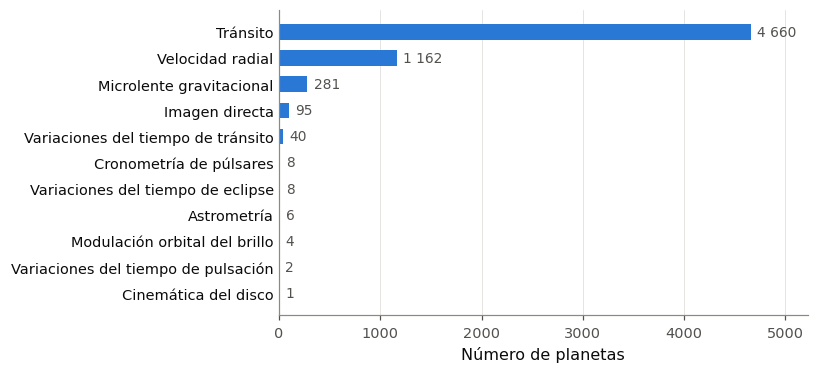

In [6]:
orden = tabla_metodo.sort_values("N_planetas")
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.barh(orden["metodo"], orden["N_planetas"], height=0.6, color=COLOR_UNICO)
for metodo, n in zip(orden["metodo"], orden["N_planetas"]):
    ax.text(n + 60, metodo, f"{n:,}".replace(",", " "), va="center", fontsize=9, color=TINTA_SECUNDARIA)
ax.set_xlabel("Número de planetas")
ax.set_xlim(0, orden["N_planetas"].max() * 1.12)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=TINTA)
guardar_figura(fig, "D-F2", "metodo_de_descubrimiento",
               titulo="Número de planetas por método de descubrimiento.", seccion="6.1.1", destino="anexo")
plt.show()

### Regímenes de radio

In [7]:
con_radio = df[df["clase_radio"] != "sin_dato"]
filas = []
for clase in CLASES_RADIO:
    d = con_radio[con_radio["clase_radio"] == clase]
    filas.append({"clase_radio": clase, "criterio": CRITERIO_CLASE[clase] + " R_Tierra",
                  "N_planetas": len(d), "porcentaje": 100 * len(d) / len(con_radio),
                  "N_estrellas": d["hostname"].nunique(), "N_en_transito": int((d["tran_flag"] == 1).sum()),
                  "pl_rade_mediana": d["pl_rade"].median(), "pl_orbper_mediana": d["pl_orbper"].median(),
                  "st_mass_mediana": d["st_mass"].median(), "st_met_mediana": d["st_met"].median()})
tabla_regimenes = guardar_tabla(
    pd.DataFrame(filas), "D-T5", "regimenes_de_radio",
    titulo="Regímenes de radio en el catálogo limpio: criterio, número de planetas y medianas de las propiedades planetarias y estelares.",
    seccion="6.1.1", decimales=3,
    nota=f"{int((df['clase_radio'] == 'sin_dato').sum())} planetas no tienen radio. Los planetas que no transitan tienen radios estimados por el archivo.",
    encabezados={"N_en_transito": "En tránsito", "pl_rade_mediana": r"$R_p$ med.", "pl_orbper_mediana": r"$P$ med.",
                 "st_mass_mediana": r"$M_\star$ med.", "st_met_mediana": "[Fe/H] med."},
    formatos={"porcentaje": "{:.1f}", "pl_rade_mediana": "{:.2f}", "pl_orbper_mediana": "{:.2f}"})
tabla_regimenes

Tabla D-T5 guardada: tablas/D-T5_regimenes_de_radio.csv


,clase_radio,criterio,N_planetas,porcentaje,N_estrellas,N_en_transito,pl_rade_mediana,pl_orbper_mediana,st_mass_mediana,st_met_mediana
0,terrestre,Rp < 1.25 R_Tierra,571,9.176,473,533,1.047,4.549,0.832,-0.02
1,supertierra,1.25 <= Rp < 2 R_Tierra,1188,19.090,1023,1125,1.590,6.453,0.890,0.00
2,neptuniano,2 <= Rp < 6 R_Tierra,2374,38.149,1904,2075,2.720,14.155,0.920,0.01
3,gigante_gaseoso,6 <= Rp < 15 R_Tierra,1853,29.777,1645,752,12.700,85.332,1.030,0.10
4,mayor_que_jupiter,Rp >= 15 R_Tierra,237,3.808,235,216,16.814,3.314,1.300,0.05


Figura D-F3 guardada: figuras/D-F3_distribucion_radio_planetario.png y .pdf


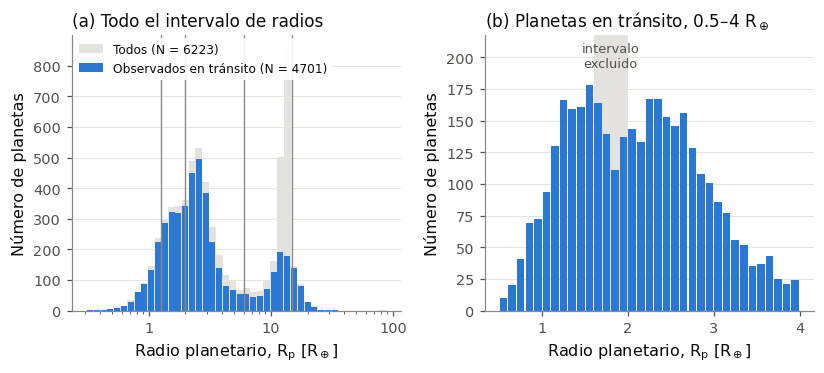

In [8]:
transito = con_radio[con_radio["tran_flag"] == 1]
fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.5))

ax = ejes[0]
intervalos = np.logspace(np.log10(con_radio["pl_rade"].min()), np.log10(con_radio["pl_rade"].max()), 45)
ax.hist(con_radio["pl_rade"], bins=intervalos, color=GRIS_CLARO, label=f"Todos (N = {len(con_radio)})")
ax.hist(transito["pl_rade"], bins=intervalos, color=COLOR_UNICO, rwidth=0.88,
        label=f"Observados en tránsito (N = {len(transito)})")
for limite in LIMITES_RADIO:
    ax.axvline(limite, color=GRIS, linewidth=0.9)
eje_log_simple(ax, "x")
ax.set_xlabel(EJE["pl_rade"])
ax.set_ylabel("Número de planetas")
ax.legend(loc="upper left", fontsize=8, borderaxespad=0.2, frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.grid(axis="x", visible=False)
etiqueta_panel(ax, "a", "Todo el intervalo de radios")

ax = ejes[1]
pequenos = transito[(transito["pl_rade"] >= 0.5) & (transito["pl_rade"] <= 4.0)]
ax.axvspan(R_VALLE_MIN, R_VALLE_MAX, color=GRIS_CLARO, zorder=0)
cuentas, _, _ = ax.hist(pequenos["pl_rade"], bins=np.arange(0.5, 4.01, 0.1), color=COLOR_UNICO, rwidth=0.88)
ax.set_ylim(0, cuentas.max() * 1.22)
ax.text((R_VALLE_MIN + R_VALLE_MAX) / 2, cuentas.max() * 1.19, "intervalo\nexcluido",
        ha="center", va="top", fontsize=8.5, color=TINTA_SECUNDARIA)
ax.set_xlabel(EJE["pl_rade"])
ax.set_ylabel("Número de planetas")
ax.grid(axis="x", visible=False)
etiqueta_panel(ax, "b", r"Planetas en tránsito, 0.5–4 $R_\oplus$")

fig.tight_layout()
guardar_figura(fig, "D-F3", "distribucion_radio_planetario",
               titulo=("Distribución del radio planetario. (a) Todo el catálogo; las líneas verticales marcan los límites de los "
                       "cinco regímenes (1.25, 2, 6 y 15 R_Tierra). (b) Planetas en tránsito entre 0.5 y 4 R_Tierra; la banda "
                       "gris marca el intervalo 1.6-2.0 R_Tierra excluido en el análisis de super-Tierras y sub-Neptunos."),
               seccion="6.1.1")
plt.show()

### Diagrama masa–radio

Solo planetas con masa verdadera (`pl_bmassprov = Mass`), observados en tránsito y sin límites en masa o radio.

Figura D-F4 guardada: figuras/D-F4_diagrama_masa_radio.png y .pdf


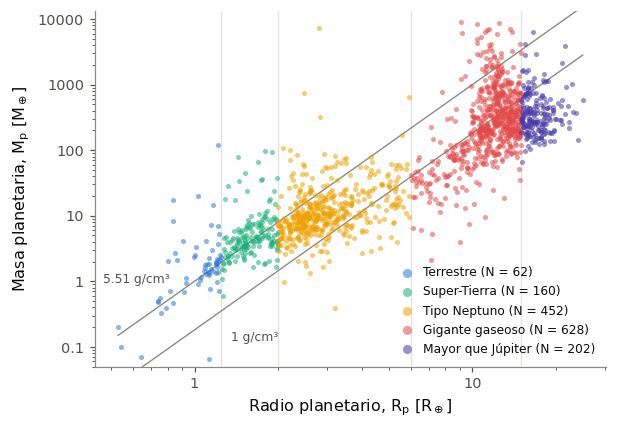

In [9]:
mr = df[(df["pl_bmassprov"] == "Mass") & (df["tran_flag"] == 1)
        & (df["pl_radelim"].fillna(0) == 0) & (df["pl_bmasselim"].fillna(0) == 0)
        & df["pl_rade"].notna() & df["pl_bmasse"].notna() & (df["clase_radio"] != "sin_dato")]

fig, ax = plt.subplots(figsize=(6.0, 4.2))
radios = np.logspace(np.log10(mr["pl_rade"].min()), np.log10(mr["pl_rade"].max()), 100)
for rho in [1.0, RHO_TIERRA]:
    ax.plot(radios, rho / RHO_TIERRA * radios ** 3, color=GRIS, linewidth=0.9, zorder=1)
for clase in CLASES_RADIO:
    d = mr[mr["clase_radio"] == clase]
    ax.scatter(d["pl_rade"], d["pl_bmasse"], s=11, color=COLOR_CLASE[clase], alpha=0.55,
               linewidths=0, label=f"{ETIQUETA_CLASE[clase]} (N = {len(d)})", zorder=2)
for limite in LIMITES_RADIO:
    ax.axvline(limite, color=GRIS_CLARO, linewidth=0.9, zorder=0)
eje_log_simple(ax, "xy")
ax.set_ylim(0.05, mr["pl_bmasse"].max() * 1.5)
ax.text(1.35, 0.11, "1 g/cm³", fontsize=8, color=TINTA_SECUNDARIA, ha="left", va="bottom")
ax.text(0.47, 0.85, "5.51 g/cm³", fontsize=8, color=TINTA_SECUNDARIA, ha="left", va="bottom")
ax.set_xlabel(EJE["pl_rade"])
ax.set_ylabel(EJE["pl_bmasse"])
ax.grid(visible=False)
ax.legend(loc="lower right", fontsize=8, markerscale=1.8, handletextpad=0.3)
guardar_figura(fig, "D-F4", "diagrama_masa_radio",
               titulo=("Diagrama masa-radio de los planetas en tránsito con masa verdadera, por régimen de radio. "
                       "Las curvas grises son líneas de densidad constante (1 y 5.51 g/cm^3)."),
               seccion="6.1.1", nota=f"N = {len(mr)} planetas.")
plt.show()

## 6.1.2 Submuestras analíticas

Cada análisis usa la submuestra que su pregunta requiere. Las definiciones están en `funciones.py`.

In [10]:
a1 = muestra_analisis_I(df)
pequenos = planetas_pequenos(df)
zoom = muestra_zoom(pequenos, "transito")
a2, _ = muestra_analisis_II(df)
candidatos, _ = planetas_candidatos_arquitectura(df)

tabla_submuestras = pd.DataFrame([
    {"analisis": "I. Regímenes de radio", "unidad": "planeta",
     "criterios": "Descubiertos por tránsito, con radio, período, masa estelar y metalicidad",
     "N_planetas": len(a1), "N_estrellas": a1["hostname"].nunique()},
    {"analisis": "I. Super-Tierras y sub-Neptunos", "unidad": "planeta",
     "criterios": "Tránsito, 1-4 R_Tierra excluyendo 1.6-2.0 R_Tierra, con flujo incidente, masa estelar y metalicidad",
     "N_planetas": len(zoom), "N_estrellas": zoom["hostname"].nunique()},
    {"analisis": "II. Propiedades físicas", "unidad": "planeta",
     "criterios": "1-4 R_Tierra, masa verdadera y radio medido sin límites, flujo incidente, masa estelar y metalicidad",
     "N_planetas": len(a2), "N_estrellas": a2["hostname"].nunique()},
    {"analisis": "III. Arquitectura", "unidad": "sistema",
     "criterios": "Al menos 2 planetas de 1-4 R_Tierra y P < 100 d, con masa estelar y metalicidad",
     "N_planetas": len(candidatos), "N_estrellas": candidatos["hostname"].nunique()},
])
tabla_submuestras = guardar_tabla(
    tabla_submuestras, "D-T8", "submuestras_analiticas",
    titulo="Submuestras utilizadas en los tres análisis.", seccion="6.1.2",
    nota="En el análisis III cada estrella es un sistema; el número de planetas es el total en esos sistemas.",
    encabezados={"unidad": "Unidad", "criterios": "Criterios de selección"})
tabla_submuestras

Tabla D-T8 guardada: tablas/D-T8_submuestras_analiticas.csv


,analisis,unidad,criterios,N_planetas,N_estrellas
0,I. Regímenes de radio,planeta,"Descubiertos por tránsito, con radio, período,...",4461,3390
1,I. Super-Tierras y sub-Neptunos,planeta,"Tránsito, 1-4 R_Tierra excluyendo 1.6-2.0 R_Ti...",2565,1981
2,II. Propiedades físicas,planeta,"1-4 R_Tierra, masa verdadera y radio medido si...",535,365
3,III. Arquitectura,sistema,Al menos 2 planetas de 1-4 R_Tierra y P < 100 ...,1513,615
